In [1]:
import sys
import os
user_site = os.path.expanduser('~/.local/lib/python3.12/site-packages')
if user_site not in sys.path:
    sys.path.insert(0, user_site)
    
sys.path.append(os.path.abspath(os.path.join('..')))

import radiomana
from torch.utils.data import ConcatDataset, Subset, Dataset
import matplotlib.pyplot as plt
import os
import numpy as np
import torch


In [2]:
os.environ['DSET_FIOT_HIGHWAY2'] = r"C:\Users\Ethan\Desktop\Purdue\datamine\fiot_highway2_f32"
os.environ['DSET_FIOT_HIGHWAY1_SUBSET'] = r'C:\Users\Ethan\Desktop\Purdue\datamine\fiot_highway1_subset'


In [3]:
# binary relabeling helpers: original class id -> 0 (background) / 1 (jammed)
class BinaryAugmentedLabels(Dataset):
    """wraps a dataset; maps original class ids to 0 (background) / 1 (jammed) with augmentations"""
    def __init__(self, base, positive, is_train=True):
        self.base = base
        self.positive = set(positive)
        self.is_train = is_train

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        x, y = self.base[i]
        label = int(int(y) in self.positive)

        # Apply augmentations only to training jammed signals
        if self.is_train and label == 1:
            if not isinstance(x, torch.Tensor):
                x = torch.tensor(x, dtype=torch.float32)
            else:
                x = x.clone()

            # 1. Random Gaussian Noise
            if torch.rand(1).item() < 0.5:
                x = x + torch.randn_like(x) * 0.05 * torch.std(x)

            # 2. Random Amplitude Scaling (0.8x to 1.2x)
            if torch.rand(1).item() < 0.5:
                x = x * (0.8 + 0.4 * torch.rand(1).item())

            # 3. Random Frequency Bin Shift
            if torch.rand(1).item() < 0.3:
                shift = torch.randint(-5, 6, (1,)).item()
                x = torch.roll(x, shifts=shift, dims=-1)

        return x, label


class JointBinaryHighwayDataModule(radiomana.HighwayDataModule):
    """DataModule that trains on Highway2 + a small slice of Highway1, and tests on remaining Highway1"""
    def __init__(self, hw1_train_ratio=0.15, batch_size=32, num_workers=0, **kwargs):
        super().__init__(batch_size=batch_size, num_workers=num_workers, **kwargs)
        self.hw1_train_ratio = hw1_train_ratio
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.positive_hw2 = {4, 5, 6, 7, 8}
        self.positive_hw1 = {3, 4, 5, 6, 7, 8, 9, 10}

    def setup(self, stage=None, **kwargs):
        # 1. Load Highway 2 (Primary Training Data)
        super().setup(stage, root_dir="DSET_FIOT_HIGHWAY2", **kwargs)
        hw2_train = BinaryAugmentedLabels(self.data_train, self.positive_hw2, is_train=True)
        hw2_val = BinaryAugmentedLabels(self.data_val, self.positive_hw2, is_train=False)

        # 2. Load Highway 1 (Target Domain)
        hw1_dm = radiomana.HighwayDataModule(batch_size=self.batch_size, num_workers=self.num_workers)
        hw1_dm.setup(stage, root_dir="DSET_FIOT_HIGHWAY1_SUBSET", **kwargs)

        # Binary wrap Highway 1 test split
        hw1_full_test = BinaryAugmentedLabels(hw1_dm.data_test, self.positive_hw1, is_train=False)

        # Split Highway 1 into a small fine-tuning slice and remaining test split
        n_hw1 = len(hw1_full_test)
        n_train = int(n_hw1 * self.hw1_train_ratio)
        n_test = n_hw1 - n_train

        g = torch.Generator().manual_seed(42)
        hw1_train_split, hw1_test_split = torch.utils.data.random_split(
            hw1_full_test, [n_train, n_test], generator=g
        )

        # Enable augmentation flag for the training portion of Highway 1
        hw1_train_split = Subset(BinaryAugmentedLabels(hw1_dm.data_test, self.positive_hw1, is_train=True), hw1_train_split.indices)

        # Combine Highway 2 training data with the 15% Highway 1 fine-tuning subset
        self.data_train = ConcatDataset([hw2_train, hw1_train_split])
        self.data_val = hw2_val
        self.data_test = hw1_test_split

In [4]:
# Initialize Joint DataModule (Highway2 + 15% Highway1 for training)
datamodule = JointBinaryHighwayDataModule(hw1_train_ratio=0.15, batch_size=32, num_workers=0)
datamodule.setup()

print("Joint Training Set Size (Highway2 + 15% Highway1):", len(datamodule.data_train))
print("Highway1 Remaining Test Samples:", len(datamodule.data_test))

# Verify a sample training batch
train_batch = next(iter(datamodule.train_dataloader()))


Joint Training Set Size (Highway2 + 15% Highway1): 12385
Highway1 Remaining Test Samples: 2953


In [5]:
import lightning as L
import torch
from radiomana.models import HighwayViTModel

# Free GPU memory
for name in ("model", "optimizer", "x", "y", "logits", "preds"):
    globals().pop(name, None)
torch.cuda.empty_cache()


class LossHistory(L.Callback):
    """records mean train loss and full test-split loss at the end of every epoch"""

    def __init__(self):
        self.train_loss, self.test_loss = [], []
        self._batch_losses = []

    def on_train_epoch_start(self, trainer, pl_module):
        self._batch_losses = []

    def on_train_batch_end(self, trainer, pl_module, outputs, batch, batch_idx):
        self._batch_losses.append(outputs["loss"].item())

    def on_train_epoch_end(self, trainer, pl_module):
        self.train_loss.append(float(np.mean(self._batch_losses)))

        pl_module.eval()
        total, count = 0.0, 0
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for x, y in trainer.datamodule.test_dataloader():
                x, y = x.to(pl_module.device), y.to(pl_module.device)
                total += pl_module.criterion(pl_module(x), y).item() * len(y)
                count += len(y)
        pl_module.train()
        self.test_loss.append(total / count)
        print(f"epoch {trainer.current_epoch}: train loss {self.train_loss[-1]:.4f}, test loss {self.test_loss[-1]:.4f}")


torch.set_float32_matmul_precision("high")
model = HighwayViTModel()
loss_history = LossHistory()
trainer = L.Trainer(
    accelerator="gpu",
    devices=1,
    max_epochs=10,
    precision="16-mixed",
    logger=False,
    enable_checkpointing=False,
    callbacks=[loss_history],
)
trainer.fit(model, datamodule=datamodule)

# ---- Binary Evaluation on Remaining Highway 1 Test Split ----
print("Highway 1 remaining test samples:", len(datamodule.data_test))

model.eval()
all_pred, all_true = [], []
with torch.no_grad():
    for x, y in datamodule.test_dataloader():
        logits = model(x.to(model.device))
        all_pred.append(logits[:, :2].argmax(dim=1).cpu())
        all_true.append(y)

pred_bin = torch.cat(all_pred)   # 0 = not jammed, 1 = jammed
true_bin = torch.cat(all_true)   # already 0/1 from the datamodule

tp = ((pred_bin == 1) & (true_bin == 1)).sum().item()
tn = ((pred_bin == 0) & (true_bin == 0)).sum().item()
fp = ((pred_bin == 1) & (true_bin == 0)).sum().item()
fn = ((pred_bin == 0) & (true_bin == 1)).sum().item()

recall = tp / max(tp + fn, 1)
precision = tp / max(tp + fp, 1)
f1 = 2 * precision * recall / max(precision + recall, 1e-9)
bal_acc = (recall + tn / max(tn + fp, 1)) / 2

print(f"confusion  TN={tn} FP={fp} FN={fn} TP={tp}")
print(f"accuracy:     {(tp + tn) / len(true_bin):.1%}")
print(f"balanced acc: {bal_acc:.1%}")
print(f"jammed precision {precision:.3f}  recall {recall:.3f}  f1 {f1:.3f}")


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loading `train_dataloader` to estimate number of stepping batches.
c:\Users\Ethan\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.
c:\Users\Ethan\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightning\pytorch\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estima

┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ criterion │ CrossEntropyLoss  │      0 │ train │     0 │
│ 1 │ submodel  │ VisionTransformer │ 85.8 M │ train │     0 │
└───┴───────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 85.8 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 85.8 M                                                                                               
Total estimated model params size (MB): 343.222                                                                    
Modules in train mode: 153                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

c:\Users\Ethan\AppData\Local\Programs\Python\Python313\Lib\site-packages\rich\live.py:231: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\Ethan\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightning\pytorch\trainer\connectors\data_
connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.

...

epoch 7: train loss 0.5352, test loss 0.6089

epoch 8: train loss 0.5315, test loss 0.5949

epoch 9: train loss 0.5279, test loss 0.5981

`Trainer.fit` stopped: `max_epochs=10` reached.


Highway 1 remaining test samples: 2953
confusion  TN=2706 FP=119 FN=42 TP=86
accuracy:     94.5%
balanced acc: 81.5%
jammed precision 0.420  recall 0.672  f1 0.517


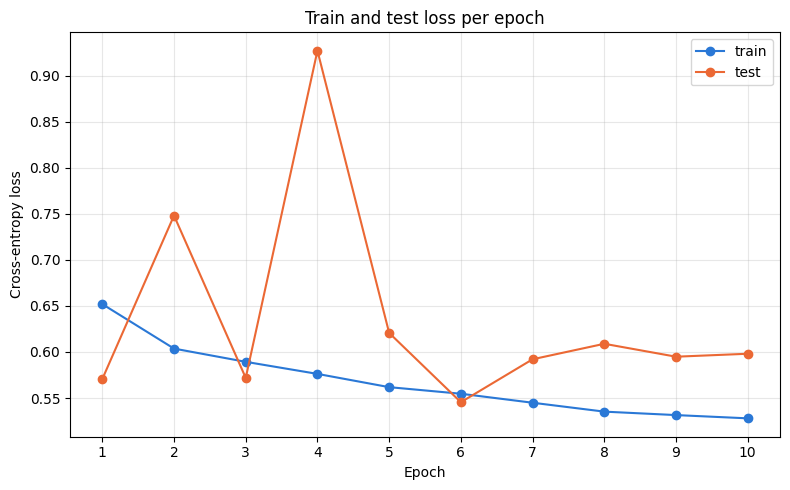

In [6]:
# Train vs test loss per epoch
epochs = range(1, len(loss_history.train_loss) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs, loss_history.train_loss, marker="o", color="#2a78d6", label="train")
ax.plot(epochs, loss_history.test_loss, marker="o", color="#eb6834", label="test")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Train and test loss per epoch")
ax.set_xticks(list(epochs))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig('train_test_loss.png', dpi=300, bbox_inches='tight')
plt.show()


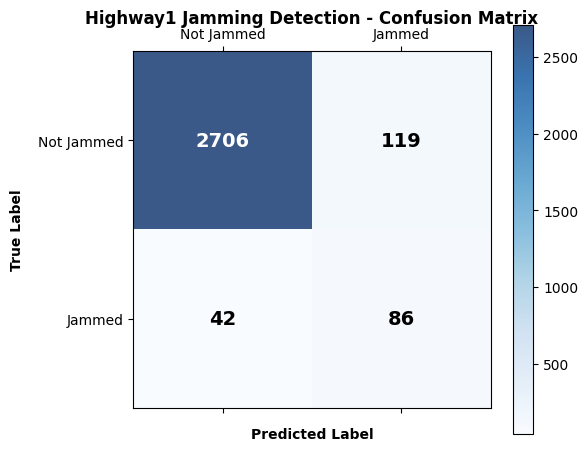

In [7]:
conf_matrix = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.8)
fig.colorbar(cax)

classes = ['Not Jammed', 'Jammed']
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes)
ax.set_yticklabels(classes)

ax.set_xlabel('Predicted Label', fontweight='bold', labelpad=10)
ax.set_ylabel('True Label', fontweight='bold', labelpad=10)
ax.set_title('Highway1 Jamming Detection - Confusion Matrix', pad=20, fontweight='bold')

for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(j, i, str(conf_matrix[i, j]), va='center', ha='center', fontsize=14, fontweight='bold',
                color='white' if conf_matrix[i, j] > (conf_matrix.max() / 2) else 'black')

plt.tight_layout()

plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
